# Testing the complete-state flow

`nb_test_flow.ipynb` for `train_flow_complete.py`: a *single* flow fit on the whole muon
state (momentum **and** production position and charge), instead of one `(pz, pt)` flow
per weight group.

The momentum comparison is the same as in `nb_test_flow.ipynb` (same
`compare_1d_histograms` / `compare_2d_histograms`). What is new is everything the
complete model adds: the position/azimuth/charge marginals and the full corner plot,
both taken from `gen_eval.py` so they are identical to what `test_flow.py` writes.

In [ ]:
import os
from time import time

import h5py
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import gen_eval as ge
from gen_eval import (load_real, real_pzpt,
                      plot_position_marginals, plot_corner_compare,
                      plot_position_xy, plot_radius_momentum, plot_position_momentum,
                      derived_position, report_position_metrics)
from models import load_flow, sample_flow
from train_flow_complete import to_physical

In [ ]:
from utils import DEFAULT_DATA
MODEL = 'outputs/flow_model_complete.pt'
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

SEED = 0

DATA_SAMPLES = 2_000_000_000
N_GEN_EXTRA = int(5e7)

ge.figs_dir = 'outputs/figs/nb_complete_'
os.makedirs('outputs/figs', exist_ok=True)

## Real data

In [3]:
# The flat table plus its weight column: every row carries its own importance weight,
# rescaled by N_total / n so the capped read still represents the full physical rate.
real, weights = load_real(DEFAULT_DATA, DATA_SAMPLES)
real_phys = real[:, :7]                       # px, py, pz, x, y, z, pdg
pz_real, pt_real = real_pzpt(real).T
print(f"real: {real_phys.shape[0]:,} muons, sum(weights) = {weights.sum():,.4g}")

Loaded 2,000,000 of 2,328,020,572 muons from /disk/users/lprate/projects/generator_muons/muons_data.h5 (sum of weights 2.823e+10)
real: 2,000,000 muons, sum(weights) = 2.823e+10


## The model

In [ ]:
flow, ckpt = load_flow(MODEL, device)
assert 'r' in ckpt['columns'], f"not a complete-state flow: {ckpt['columns']}"
print(f"columns: {' '.join(ckpt['columns'])}  |  dim={flow.dim}  |  on {device}")

In [ ]:
rng = np.random.default_rng(SEED)

def sample_muons(n):
    """n generated muons as physical (px, py, pz, x, y, z, pdg), the layout gen_eval's
    plots expect."""
    return sample_flow(flow, ckpt, n, lambda s: to_physical(s, ckpt, rng))

In [ ]:
# One generated sample matched to the real count, used by every plot below.
torch.manual_seed(SEED)
t0 = time()
gen_phys = sample_muons(real_phys.shape[0])
gen_pz, gen_pt = gen_phys[:, 2], np.hypot(gen_phys[:, 0], gen_phys[:, 1])
print(f"generated {gen_phys.shape[0]:,} muons in {time() - t0:.1f}s")
print(f"|p| max = {np.linalg.norm(gen_phys[:, :3], axis=1).max():.1f} GeV "
      f"(the simulation accepts up to 400)")

## Momentum

`compare_1d_histograms` and `compare_2d_histograms` exactly as in `nb_test_flow.ipynb`.

In [7]:
from matplotlib.colors import LogNorm

def compare_1d_histograms(real_sample, gen_sample, bins=120, range_vals=None, xlabel="Value", real_w=None):
    """Overlays 1D distributions of real and generated samples."""
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # Auto-detect range if none is provided
    if range_vals is None:
        range_vals = (min(np.min(real_sample), np.min(gen_sample)), 
                      max(np.max(real_sample), np.max(gen_sample)))
        
    b = np.linspace(range_vals[0], range_vals[1], bins)
    
    # Plot marginals
    ax.hist(real_sample, bins=b, weights=real_w, density=True, 
            histtype='step', color='k', label='Real')
    ax.hist(gen_sample, bins=b, density=True, 
            histtype='step', color='C1', label='Generated')
    
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel('Density', fontsize=14)
    ax.legend(fontsize=11)
    
    fig.tight_layout()
    return fig, ax


def compare_2d_histograms(real_pz, real_pt, gen_pz, gen_pt, gen_pz_2 = None, gen_pt_2 = None, real_w=None):
    """Creates side-by-side 2D Pz-Pt density histograms with a shared color scale."""
    pz_bins = np.linspace(0, 400, 201)
    pt_bins = np.linspace(0, 13, 201)
    
    n_plots = 2 if gen_pz_2 is None else 3
    # Calculate 2D densities
    Hr, _, _ = np.histogram2d(real_pz, real_pt, bins=[pz_bins, pt_bins], 
                              weights=real_w, density=True)
    Hg, _, _ = np.histogram2d(gen_pz, gen_pt, bins=[pz_bins, pt_bins], 
                              density=True)
    if gen_pz_2 is not None:
        Hg2, _, _ = np.histogram2d(gen_pz_2, gen_pt_2, bins=[pz_bins, pt_bins], 
                                   density=True)
    
    # Shared LogNorm for accurate visual comparison
    pos_vals = np.concatenate([Hr[Hr > 0].ravel(), Hg[Hg > 0].ravel()])
    pos_vals = np.concatenate([pos_vals, Hg2[Hg2 > 0].ravel()]) if gen_pz_2 is not None else pos_vals
    norm = LogNorm(vmin=pos_vals.min(), vmax=pos_vals.max())
    sizes = [real_pz.shape[0], gen_pz.shape[0]] if gen_pz_2 is None else [real_pz.shape[0], gen_pz.shape[0], gen_pz_2.shape[0]]
    
    fig, axes = plt.subplots(1, n_plots, figsize=(12, 5), constrained_layout=True)
    
    # Draw meshes
    Hs = [Hr, Hg] if gen_pz_2 is None else [Hr, Hg, Hg2]
    titles = ['Real (n = {})'.format(sizes[0]), 'Generated (n = {})'.format(sizes[1])] if gen_pz_2 is None else ['Real (n = {})'.format(sizes[0]), 'Generated (n = {})'.format(sizes[1]), 'Generated Extra (n = {})'.format(sizes[2])]
    for ax, H, title in zip(axes, Hs, titles):
        im = ax.pcolormesh(pz_bins, pt_bins, H.T, cmap='viridis', norm=norm)
        ax.set_xlim(0, 400)
        ax.set_ylim(0, 13)
        ax.set_xlabel('$P_z$ [GeV]', fontsize=14)
        ax.set_ylabel('$P_t$ [GeV]', fontsize=14)
        ax.set_title(title, fontsize=14)
        
    # Shared colorbar
    fig.colorbar(im, ax=axes.tolist(), label='Density')
    
    return fig, axes

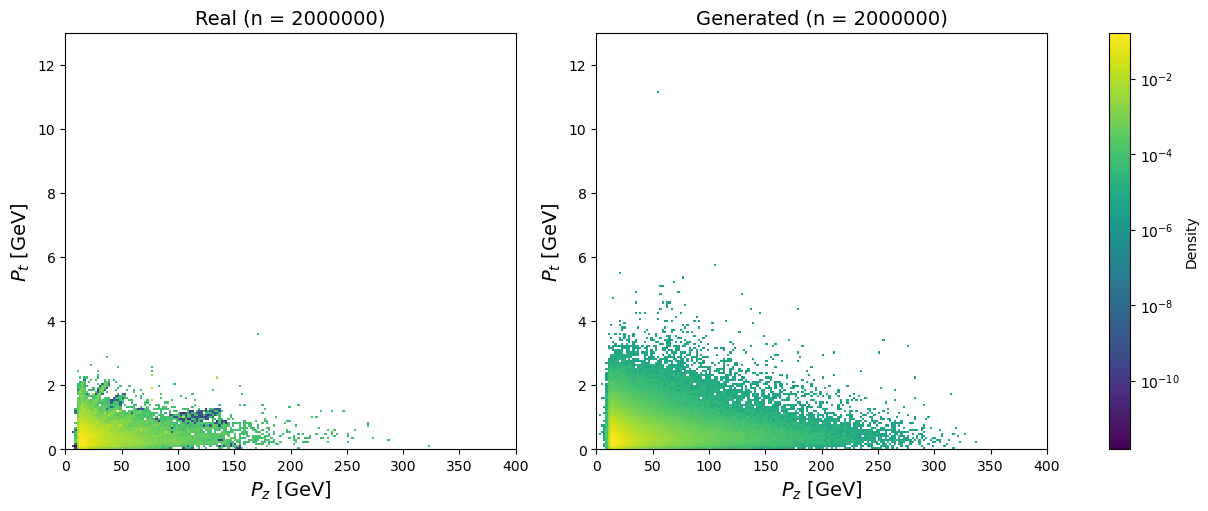

In [8]:
compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt, real_w=weights)
plt.show()

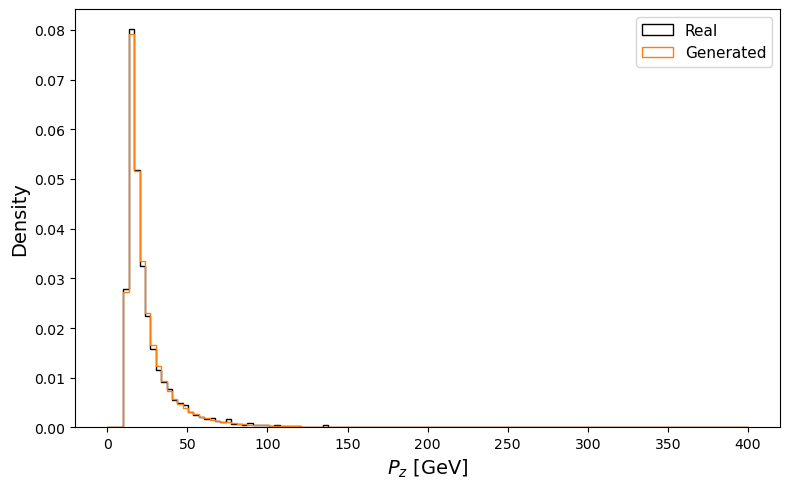

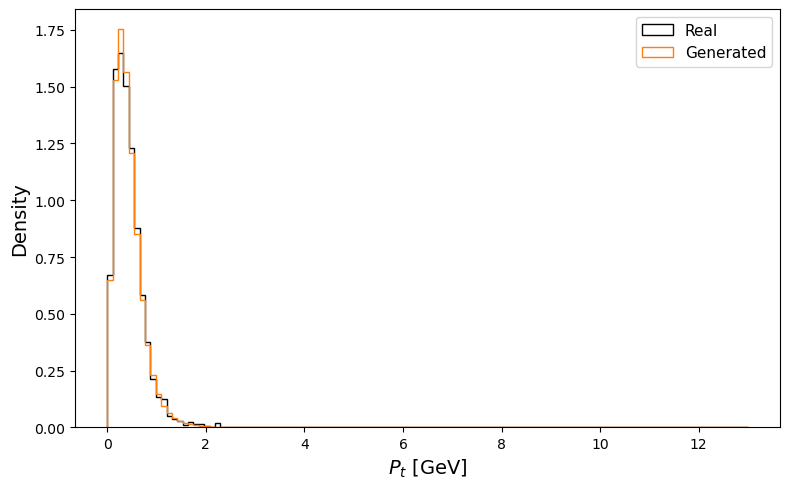

In [9]:
compare_1d_histograms(pz_real, gen_pz, range_vals=(0, 400), xlabel='$P_z$ [GeV]', real_w=weights)
plt.show()
compare_1d_histograms(pt_real, gen_pt, range_vals=(0, 13), xlabel='$P_t$ [GeV]', real_w=weights)
plt.show()

In [ ]:
# A much larger generated sample next to the matched one: the third panel shows what the
# model's density looks like once sampling noise is gone.
t0 = time()
extra = sample_muons(N_GEN_EXTRA)
gen_pz_extra, gen_pt_extra = extra[:, 2], np.hypot(extra[:, 0], extra[:, 1])
del extra
print(f"generated {gen_pz_extra.shape[0]:,} extra (pz, pt) in {time() - t0:.1f}s")

compare_2d_histograms(pz_real, pt_real, gen_pz, gen_pt,
                      gen_pz_2=gen_pz_extra, gen_pt_2=gen_pt_extra, real_w=weights)
plt.show()

## Marginals

Everything the position part of the flow models -- x, y, z, r (log axis: it spans
decades), |dphi| and charge -- plus px, py, pz, which the position parameterization feeds
into. Real is rate-weighted, generated is not (it is already drawn from the rate
density).

  saved plot [1]: outputs/figs/nb_complete_marginals.png


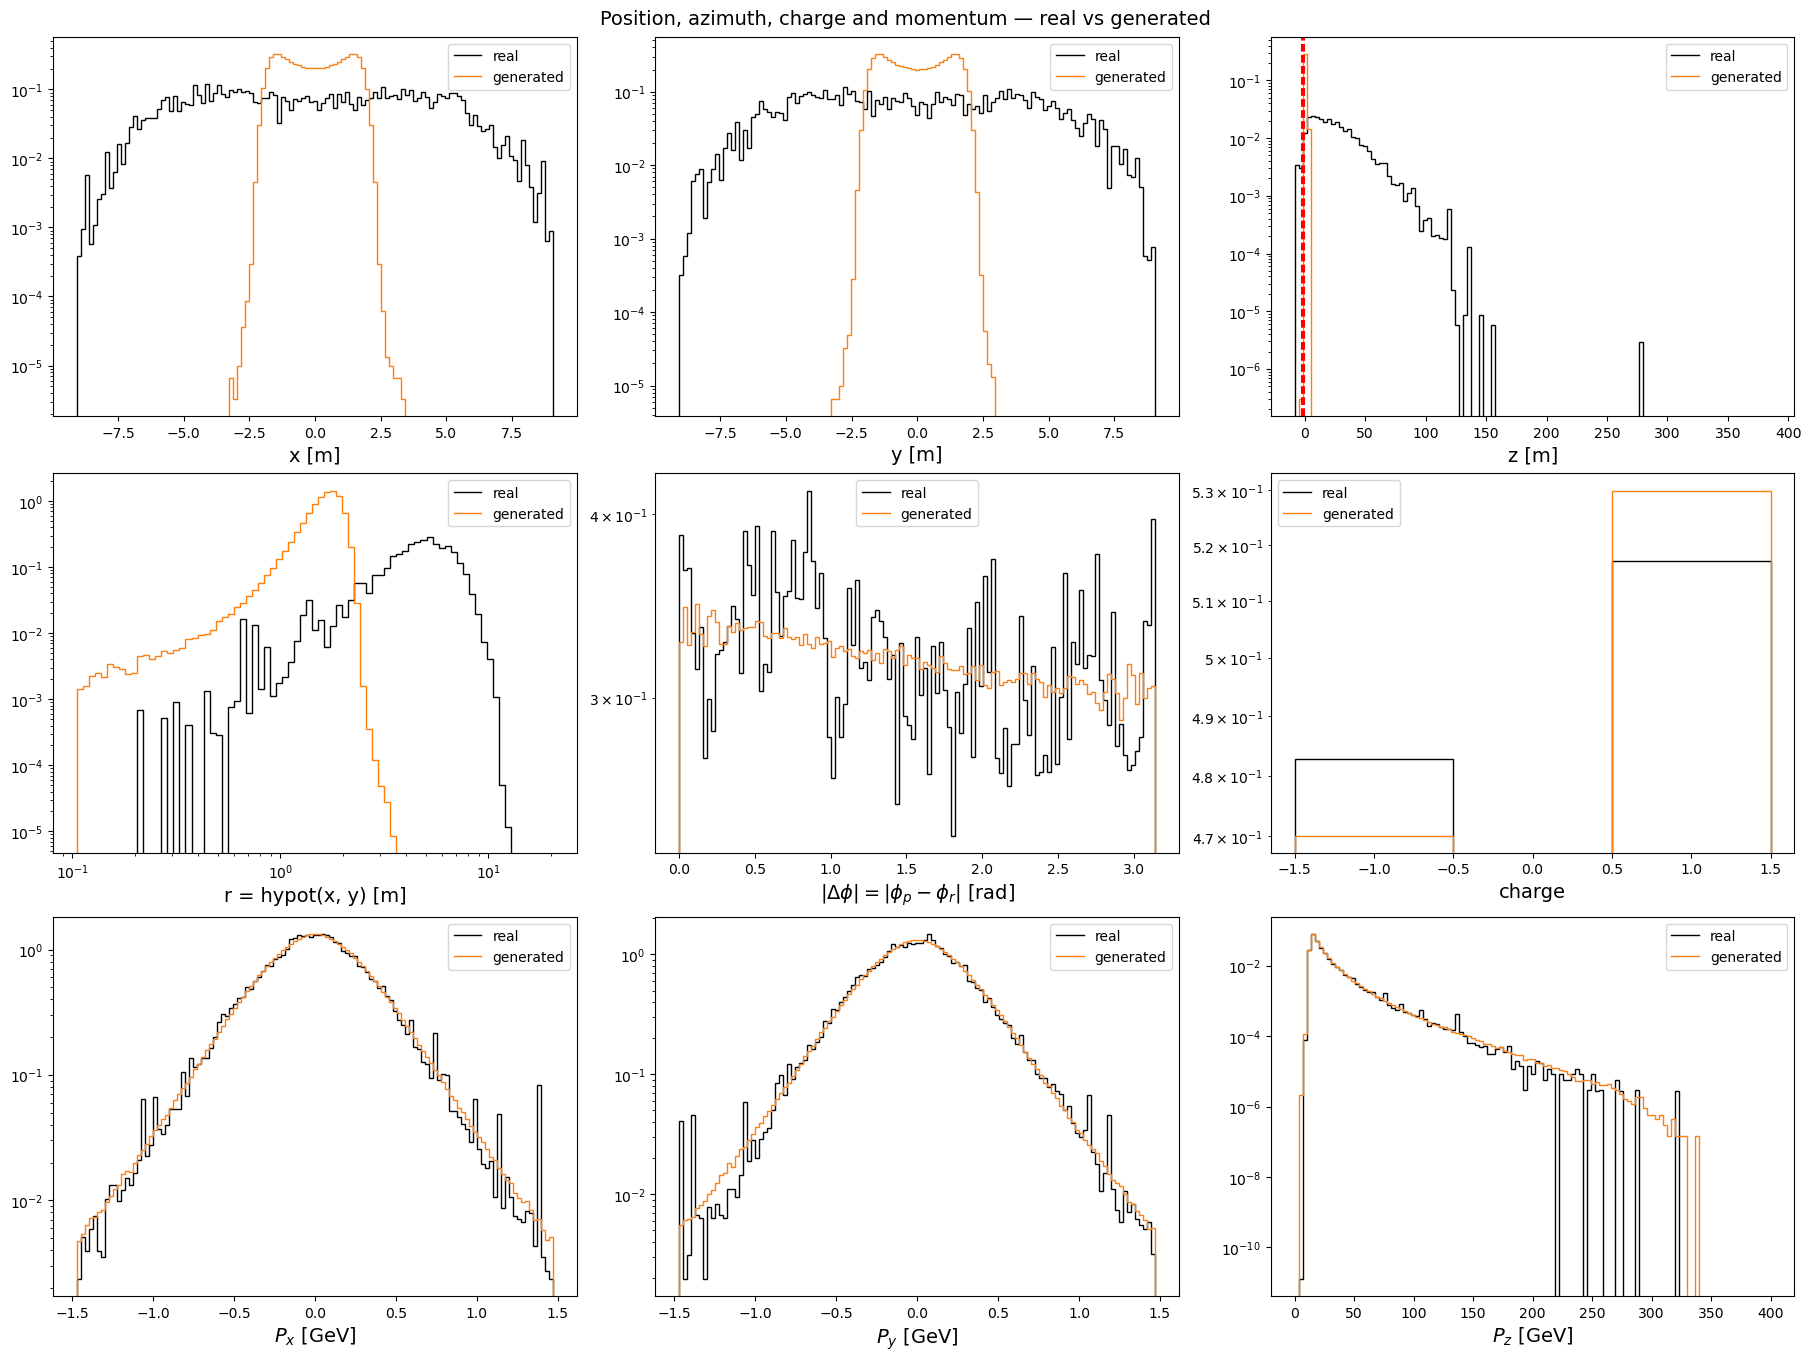

  W1(x) = 0.5954
  W1(y) = 0.5910
  W1(z) = 1.2127
  W1(log10 r) = 3.3565
  W1(|dphi|) = 0.0140
  W1(px) = 0.0225
  W1(py) = 0.0158
  W1(pz) = 0.0137


In [11]:
pos_metrics = plot_position_marginals(real_phys, gen_phys, weights, show=True)
for k, v in pos_metrics.items():
    print(f"  W1({k}) = {v:.4f}")

## Corner plot

Every pair of (x, y, z, px, py, pz): real above the diagonal, generated below it, 1D
marginals of both on the diagonal. Each mirrored pair shares one log colour scale, so
real and generated are comparable panel by panel; different pairs are not.

  saved plot [2]: outputs/figs/nb_complete_corner.png


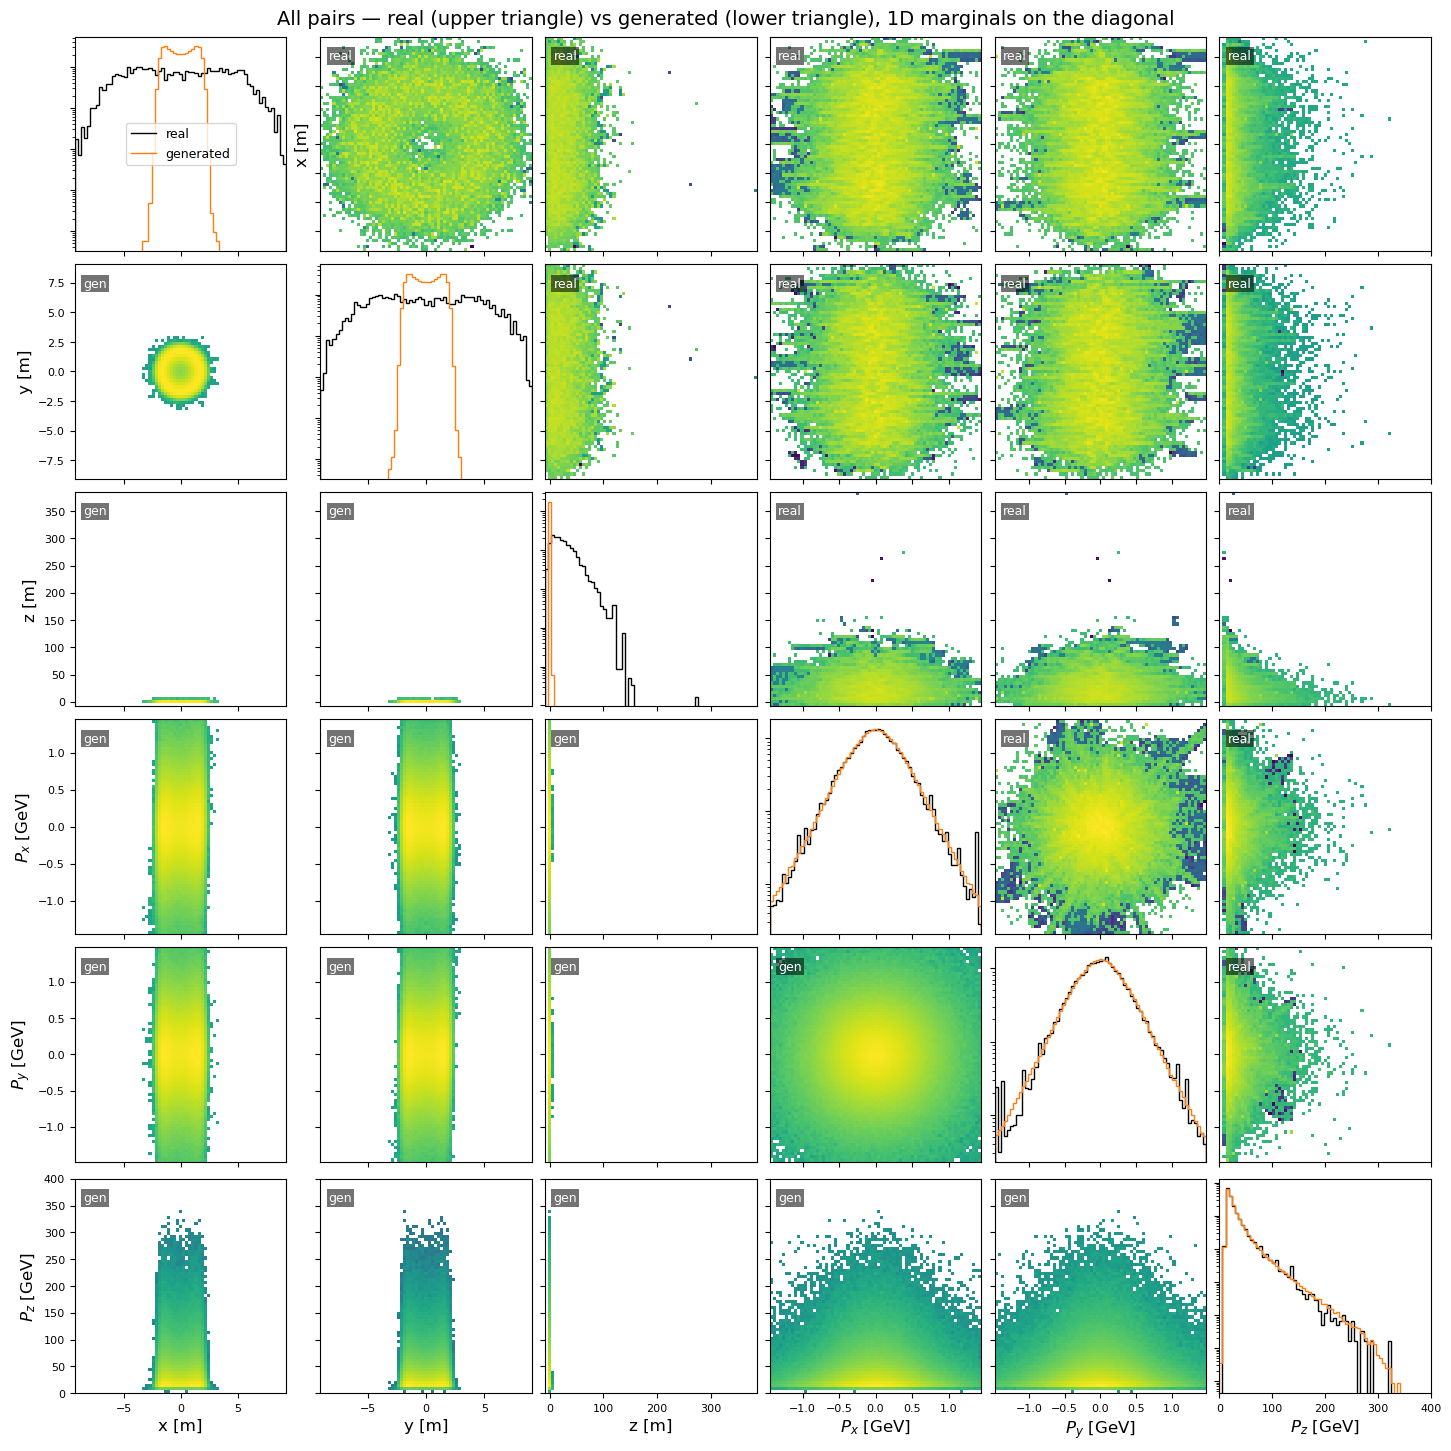

In [12]:
plot_corner_compare(real_phys, gen_phys, weights, show=True)

## Position, in detail

The x-y density, the correlations the (r, |dphi|) parameterization exists to capture,
and position against momentum.

  saved plot [3]: outputs/figs/nb_complete_position_xy.png


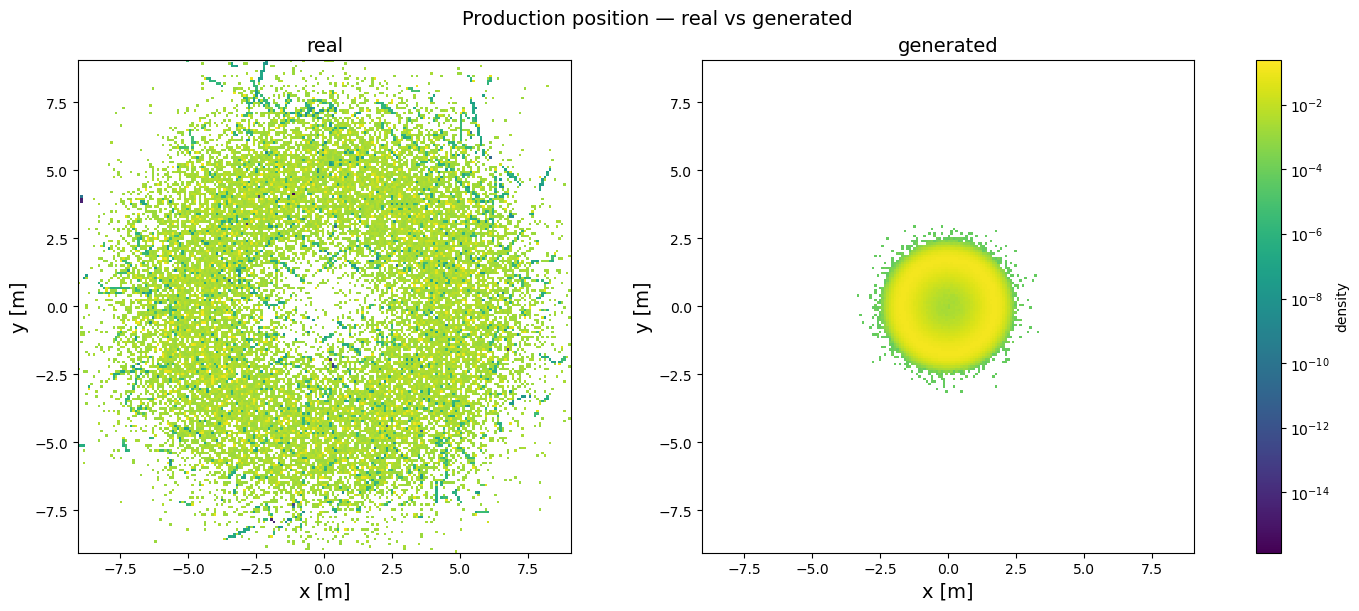

In [13]:
plot_position_xy(real_phys, gen_phys, weights, show=True)

  saved plot [4]: outputs/figs/nb_complete_radius_Pz.png


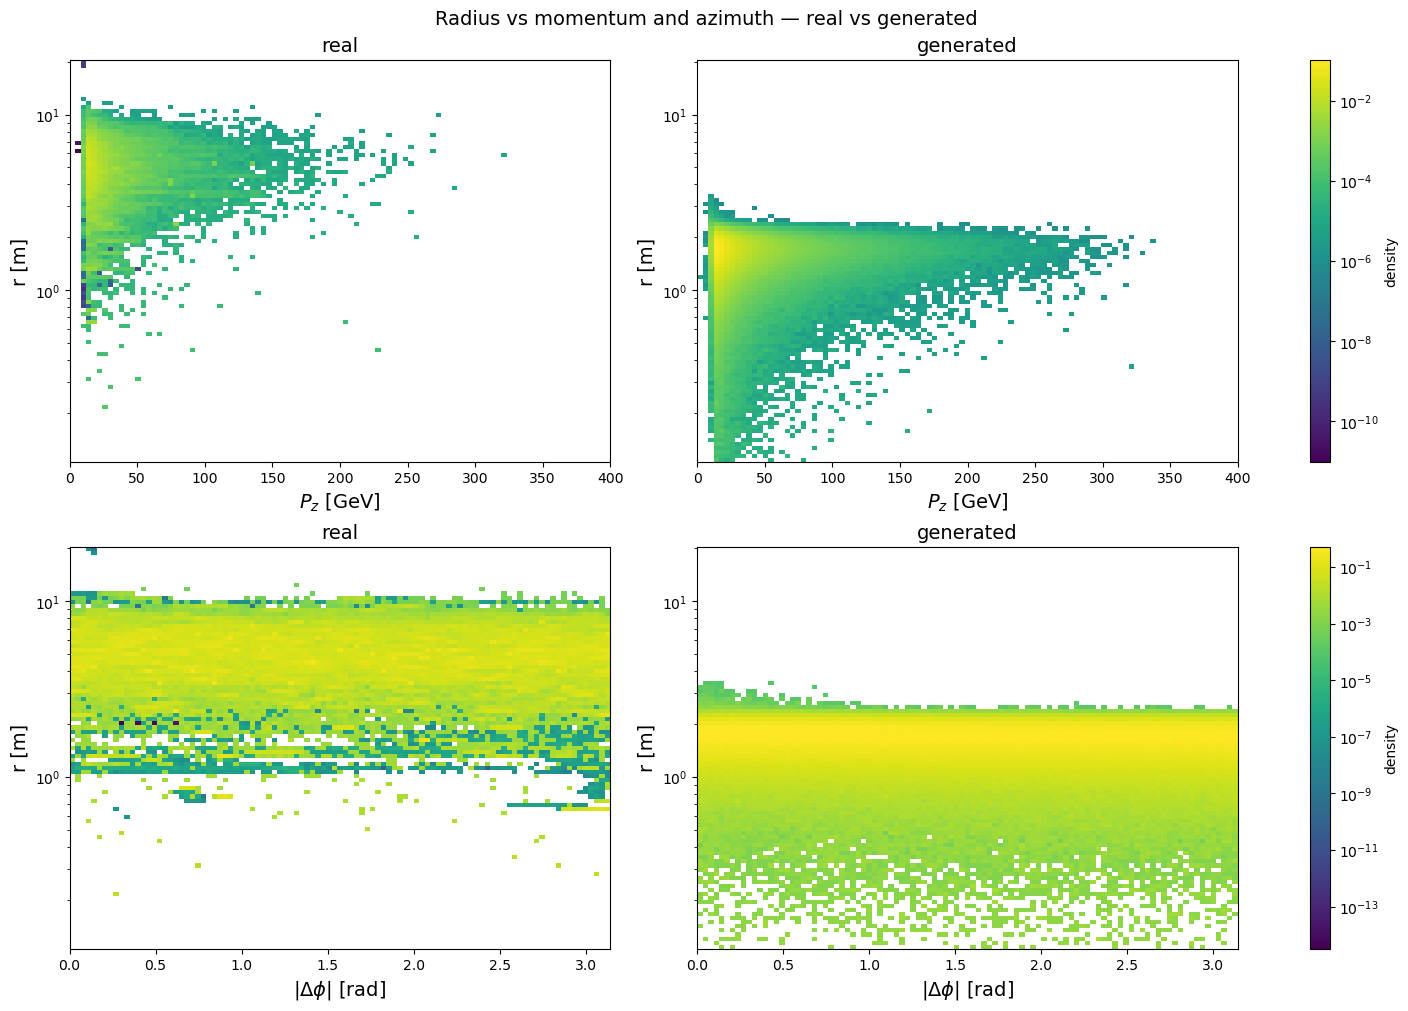

  saved plot [5]: outputs/figs/nb_complete_position_momentum.png


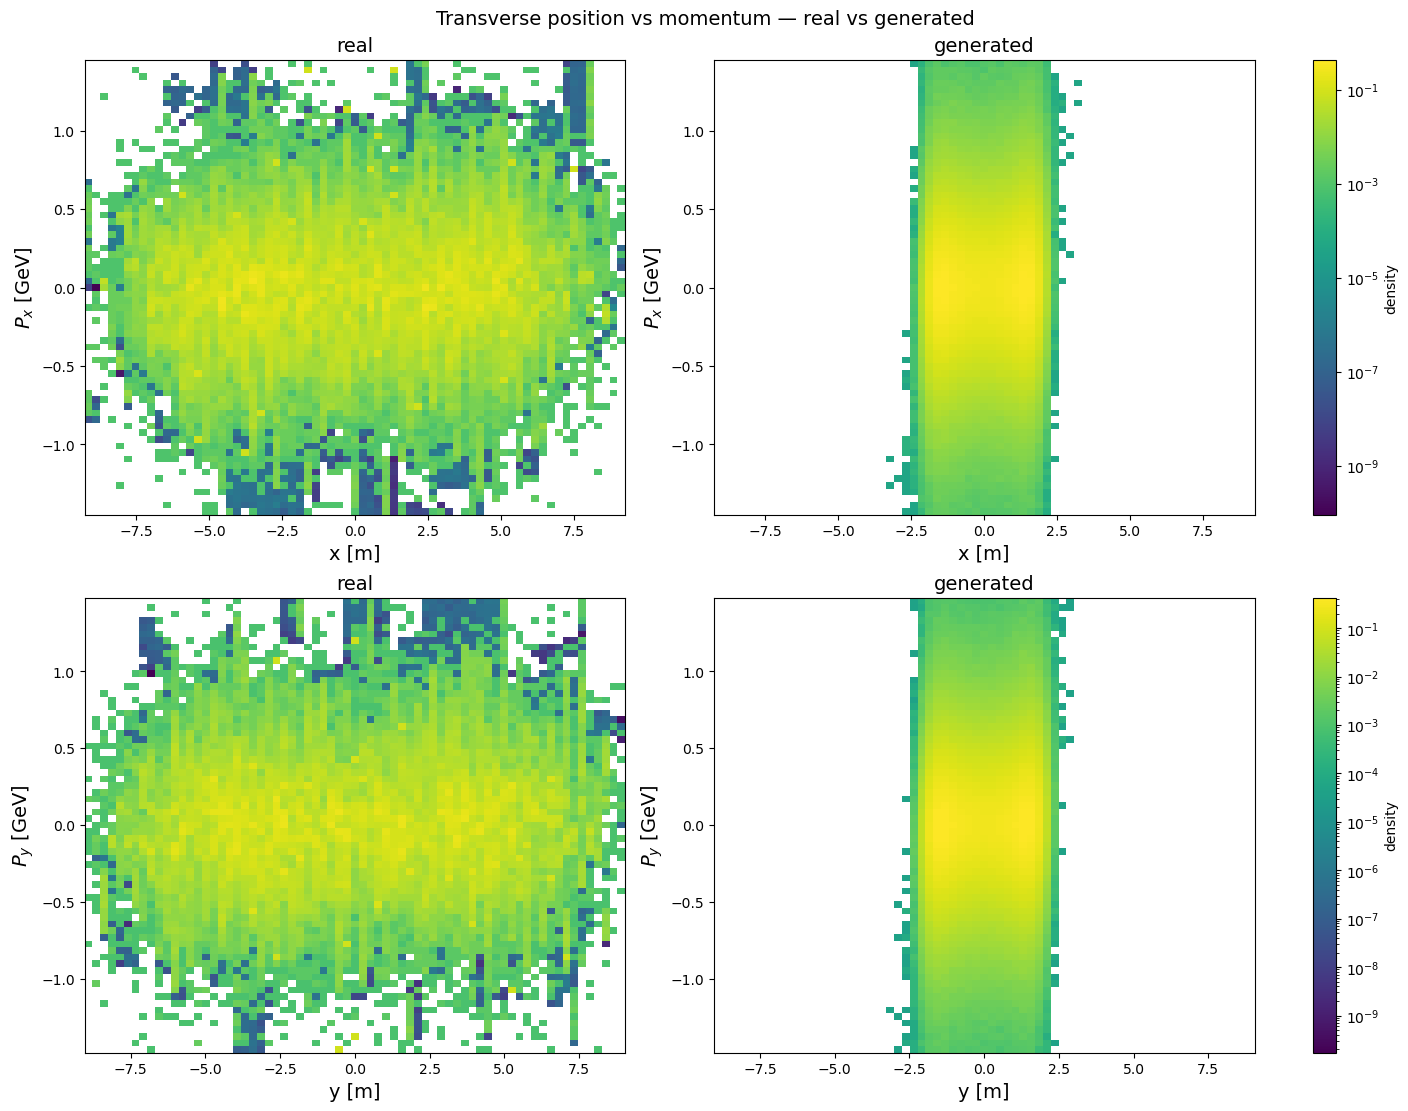

In [14]:
plot_radius_momentum(real_phys, gen_phys, weights, show=True)
plot_position_momentum(real_phys, gen_phys, weights, show=True)

In [15]:
# <cos dphi>: the single number the (r, |dphi|) parameterization is there for.
_, dphi_real, _ = derived_position(real_phys)
_, dphi_gen, _ = derived_position(gen_phys)
report_position_metrics(pos_metrics,
                        np.average(np.cos(dphi_real), weights=weights),
                        float(np.cos(dphi_gen).mean()))


Position / charge comparison:
          <cos dphi>: real=+0.0322  generated=+0.0249
  normalized W1 (lower = better):
                   x: 0.5954
                   y: 0.5910
                   z: 1.2127
             log10 r: 3.3565
              |dphi|: 0.0140
                  px: 0.0225
                  py: 0.0158
                  pz: 0.0137
